# Automated Measurement of Knee Joint Space Width
## Localization

### Imports

In [ ]:
%%writefile requirements.txt
pillow
numpy
opencv-python
ultralytics

Writing requirements.txt


In [ ]:
!pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 27.1 MB/s eta 0:00:00


In [ ]:
import os

import numpy as np
from PIL import Image, ImageEnhance, ImageFilter
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


### Data Retrieval

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir '/content/data'
!unzip "/content/drive/MyDrive/RAI_KneeJointSpace/data/jsw_dataset_final.zip" -d "/content/data"

Mounted at /content/drive
Archive:  /content/drive/MyDrive/RAI_KneeJointSpace/data/jsw_dataset_final.zip
   creating: /content/data/test/
   creating: /content/data/train/
   creating: /content/data/val/
   creating: /content/data/test/images/
   creating: /content/data/test/images_side/
   creating: /content/data/test/labels/
   creating: /content/data/test/masks/
  inflating: /content/data/test/jsw_measurements.csv  
  inflating: /content/data/test/labels/9433580.txt  
  inflating: /content/data/test/labels/9275159.txt  
  inflating: /content/data/test/labels/9734247.txt  
  inflating: /content/data/test/labels/9169092.txt  
  inflating: /content/data/test/labels/9436006.txt  
  inflating: /content/data/test/labels/9256066.txt  
  inflating: /content/data/test/labels/9438742.txt  
  inflating: /content/data/test/labels/9797760.txt  
  inflating: /content/data/test/labels/9731542.txt  
  inflating: /content/data/test/labels/9225871.txt  
  inflating: /content/data/test/labels/9411118.

In [ ]:
import os
import shutil

base_dir = "data"

# new structure
new_images_dir = os.path.join(base_dir, "images")
new_labels_dir = os.path.join(base_dir, "labels")

splits = ["train", "val", "test"]

for split in splits:
    # source dirs
    src_images = os.path.join(base_dir, split, "images")
    src_labels = os.path.join(base_dir, split, "labels")

    # target dirs
    dst_images = os.path.join(new_images_dir, split)
    dst_labels = os.path.join(new_labels_dir, split)

    os.makedirs(dst_images, exist_ok=True)
    os.makedirs(dst_labels, exist_ok=True)

    # copy images
    for file in os.listdir(src_images):
        shutil.copy(os.path.join(src_images, file), dst_images)

    # copy labels
    for file in os.listdir(src_labels):
        shutil.copy(os.path.join(src_labels, file), dst_labels)

print("✅ Dataset reorganized into YOLO format!")


✅ Dataset reorganized into YOLO format!


### Training

In [ ]:
DATASET_PATH = "/content/data/dataset.yaml"

model = YOLO("yolo11n.yaml")


In [ ]:
model.train(data=DATASET_PATH, epochs=150, batch=16, imgsz=640, val=True)

Ultralytics 8.3.182 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/dataset.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.yaml, momentum=0.937, mosaic=1.0, multi_scale=False, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12.0, pretraine

Overriding model.yaml nc=80 with nc=1

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      6640  ultralytics.nn.modules.block.C3k2            [32, 64, 1, False, 0.25]      
  3                  -1  1     36992  ultralytics.nn.modules.conv.Conv             [64, 64, 3, 2]                
  4                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  5                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  6                  -1  1     87040  ultralytics.nn.modules.block.C3k2            [128, 128, 1, True]           
  7                  -1  1    295424  ultralytics

YOLO11n summary: 181 layers, 2,590,035 parameters, 2,590,019 gradients, 6.4 GFLOPs

Freezing layer 'model.23.dfl.conv.weight'
AMP: running Automatic Mixed Precision (AMP) checks...


AMP: checks passed ✅
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4362.9±933.9 MB/s, size: 1976.3 KB)


train: Scanning /content/data/labels/train... 331 images, 0 backgrounds, 0 corrupt: 100%|██████████| 331/331 [00:01<00:00, 328.74it/s]

...

    150/150      4.62G     0.3199     0.2123     0.9432         22        640: 100%|██████████| 21/21 [00:19<00:00,  1.08it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 2/2 [00:00<00:00,  3.96it/s]


                   all         43         86      0.999          1      0.995      0.961

150 epochs completed in 0.926 hours.
Optimizer stripped from runs/detect/train/weights/last.pt, 5.5MB
Optimizer stripped from runs/detect/train/weights/best.pt, 5.5MB

Validating runs/detect/train/weights/best.pt...
Ultralytics 8.3.182 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 2/2 [00:00<00:00,  2.77it/s]


                   all         43         86      0.999          1      0.995      0.969
Speed: 0.3ms preprocess, 4.1ms inference, 0.0ms loss, 4.2ms postprocess per image
Results saved to runs/detect/train


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d9e556e14c0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.048048, 

In [ ]:
import locale
locale.getpreferredencoding = lambda: "UTF-8"
!zip -r "/content/runs.zip" "/content/runs"

  adding: content/runs/ (stored 0%)
  adding: content/runs/detect/ (stored 0%)
  adding: content/runs/detect/train2/ (stored 0%)
  adding: content/runs/detect/train2/results.png (deflated 9%)
  adding: content/runs/detect/train2/confusion_matrix.png (deflated 36%)
  adding: content/runs/detect/train2/F1_curve.png (deflated 20%)
  adding: content/runs/detect/train2/val_batch0_pred.jpg (deflated 8%)
  adding: content/runs/detect/train2/train_batch1.jpg (deflated 3%)
  adding: content/runs/detect/train2/train_batch4062.jpg (deflated 7%)
  adding: content/runs/detect/train2/results.csv (deflated 63%)
  adding: content/runs/detect/train2/train_batch4060.jpg (deflated 13%)
  adding: content/runs/detect/train2/labels.jpg (deflated 35%)
  adding: content/runs/detect/train2/events.out.tfevents.1738527865.4c36204cb861.768.0 (deflated 88%)
  adding: content/runs/detect/train2/val_batch2_pred.jpg (deflated 11%)
  adding: content/runs/detect/train2/P_curve.png (deflated 26%)
  adding: content/runs/

### Evaluation

In [ ]:
metrics = model.val(split="test")
print(metrics)


Ultralytics 8.3.182 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2098.7±1359.4 MB/s, size: 2031.1 KB)


val: Scanning /content/data/labels/test... 40 images, 0 backgrounds, 0 corrupt: 100%|██████████| 40/40 [00:00<00:00, 182.52it/s]

val: New cache created: /content/data/labels/test.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 3/3 [00:06<00:00,  2.20s/it]


                   all         40         80      0.999          1      0.995      0.964
Speed: 3.7ms preprocess, 14.2ms inference, 0.0ms loss, 3.5ms postprocess per image
Results saved to runs/detect/train2
ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d9e4ec73620>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.03

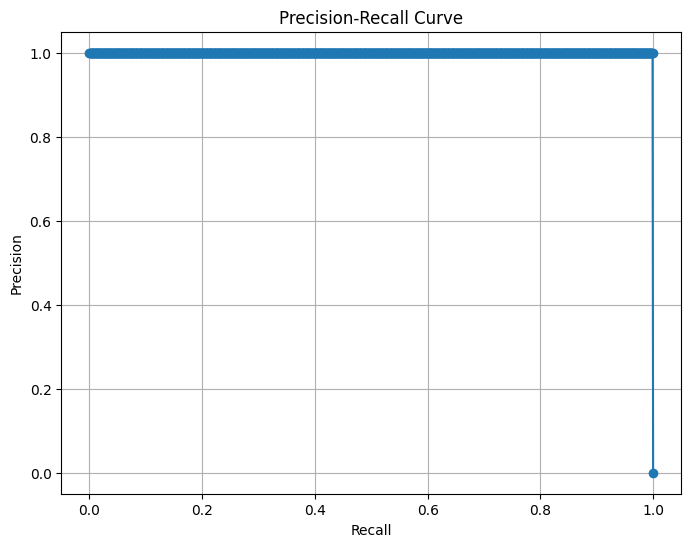

In [ ]:
%matplotlib inline

pr_curve = metrics.curves_results[0]
confidence_values = pr_curve[0]

precision_values = pr_curve[1][0]

recall_value = metrics.results_dict.get("metrics/recall(B)", None)

recall_values = np.linspace(0, recall_value, len(precision_values)) if recall_value else np.linspace(0, 1, len(precision_values))

plt.figure(figsize=(8, 6))
plt.plot(recall_values, precision_values, marker='o', linestyle='-')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid()
plt.show()


In [ ]:
print(metrics.results_dict)

{'metrics/precision(B)': np.float64(0.9993007003446882), 'metrics/recall(B)': np.float64(1.0), 'metrics/mAP50(B)': np.float64(0.995), 'metrics/mAP50-95(B)': np.float64(0.9637322976026581), 'fitness': np.float64(0.9668590678423924)}


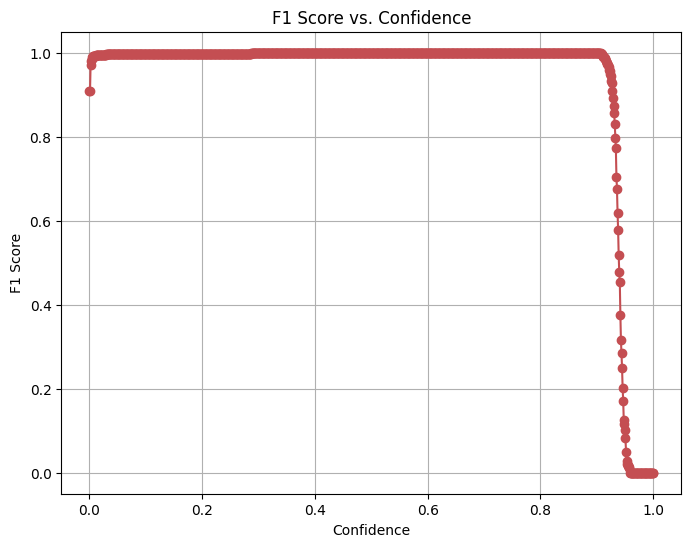

In [ ]:
f1_curve = metrics.curves_results[1]
confidence_values = f1_curve[0]
f1_scores = f1_curve[1][0]

plt.figure(figsize=(8, 6))
plt.plot(confidence_values, f1_scores, marker='o', linestyle='-', color='r')
plt.xlabel('Confidence')
plt.ylabel('F1 Score')
plt.title('F1 Score vs. Confidence')
plt.grid()
plt.show()

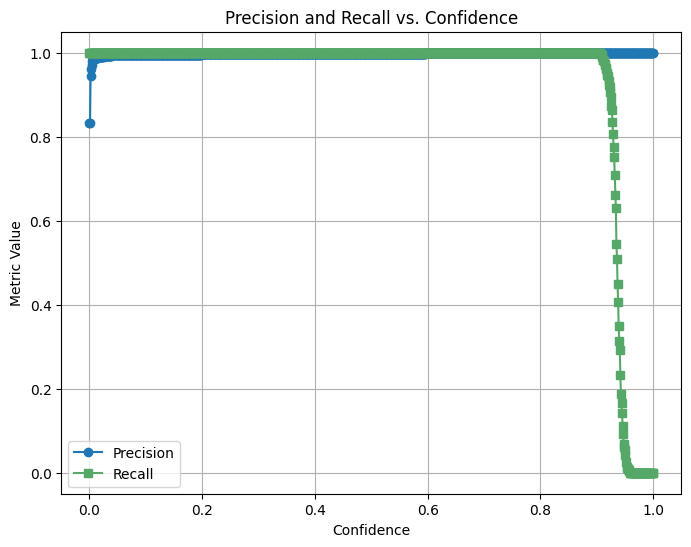

In [ ]:
precision_curve = metrics.curves_results[2]
recall_curve = metrics.curves_results[3]

confidence_values = precision_curve[0]

precision_values = precision_curve[1][0]
recall_values = recall_curve[1][0]

plt.figure(figsize=(8, 6))
plt.plot(confidence_values, precision_values, marker='o', linestyle='-', label='Precision')
plt.plot(confidence_values, recall_values, marker='s', linestyle='-', label='Recall', color='g')
plt.xlabel('Confidence')
plt.ylabel('Metric Value')
plt.title('Precision and Recall vs. Confidence')
plt.legend()
plt.grid()
plt.show()

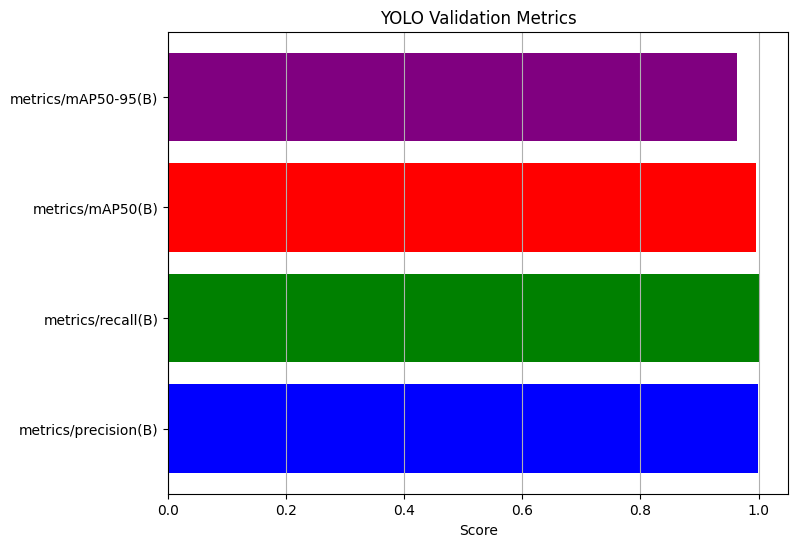

In [ ]:
results = metrics.results_dict

plt.figure(figsize=(8, 6))
metric_names = list(results.keys())[:-1]
metric_values = list(results.values())[:-1]

plt.barh(metric_names, metric_values, color=['blue', 'green', 'red', 'purple'])
plt.xlabel('Score')
plt.title('YOLO Validation Metrics')
plt.grid(axis='x')
plt.show()